In [1]:
import joblib
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn import metrics

In [2]:
df = pd.read_csv('C:/Users/guilherme_doge1/Desktop/Ciência de Dados/Aula 15 - 23-11-2026/dados_fabrica_limpos.csv', sep=',')

In [3]:
display(df.head())

,id_registro,timestamp,id_maquina,turno,temperatura_operacao_c,vibracao_mms,corrente_eletrica_a,rotacao_rpm,pressao_hidraulica_bar,consumo_energia_kwh,desgaste_ferramenta_pct,status_falha
0,1,2026-10-01 06:00:00,Prensa_Hidraulica_02,Manhã,75.47,4.30,31.09,1495.85,153.86,25.16,28.6,0
1,2,2026-10-01 06:01:00,Robo_Solda_05,Manhã,86.23,3.23,41.31,1495.85,83.41,26.27,28.6,0
2,3,2026-10-01 06:02:00,Injetora_Plastico_04,Manhã,71.84,1.14,40.23,1495.85,159.75,31.20,28.6,0
3,4,2026-10-01 06:03:00,Fresadora_CNC_03,Manhã,64.37,6.10,48.78,1495.85,149.04,38.09,28.6,0
4,5,2026-10-01 06:04:00,Torno_CNC_01,Manhã,71.06,4.51,39.31,1495.85,110.90,28.05,28.6,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id_registro              5000 non-null   int64  
 1   timestamp                5000 non-null   object 
 2   id_maquina               5000 non-null   object 
 3   turno                    5000 non-null   object 
 4   temperatura_operacao_c   5000 non-null   float64
 5   vibracao_mms             5000 non-null   float64
 6   corrente_eletrica_a      5000 non-null   float64
 7   rotacao_rpm              5000 non-null   float64
 8   pressao_hidraulica_bar   5000 non-null   float64
 9   consumo_energia_kwh      5000 non-null   float64
 10  desgaste_ferramenta_pct  5000 non-null   float64
 11  status_falha             5000 non-null   int64  
dtypes: float64(7), int64(2), object(3)
memory usage: 468.9+ KB


In [5]:
display(df.corr(numeric_only = True))

,id_registro,temperatura_operacao_c,vibracao_mms,corrente_eletrica_a,rotacao_rpm,pressao_hidraulica_bar,consumo_energia_kwh,desgaste_ferramenta_pct,status_falha
id_registro,1.000000,0.029469,0.020790,0.017200,-0.040435,0.018624,0.006257,NaN,0.014302
temperatura_operacao_c,0.029469,1.000000,0.331290,0.400959,-0.136972,0.329932,0.503371,NaN,0.394943
vibracao_mms,0.020790,0.331290,1.000000,0.339456,-0.193144,0.260926,0.371718,NaN,0.346098
corrente_eletrica_a,0.017200,0.400959,0.339456,1.000000,-0.157947,0.373271,0.880203,NaN,0.331768
rotacao_rpm,-0.040435,-0.136972,-0.193144,-0.157947,1.000000,-0.447691,-0.059556,NaN,-0.142060
pressao_hidraulica_bar,0.018624,0.329932,0.260926,0.373271,-0.447691,1.000000,0.450236,NaN,0.231280
consumo_energia_kwh,0.006257,0.503371,0.371718,0.880203,-0.059556,0.450236,1.000000,NaN,0.347066
desgaste_ferramenta_pct,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
status_falha,0.014302,0.394943,0.346098,0.331768,-0.142060,0.231280,0.347066,NaN,1.000000


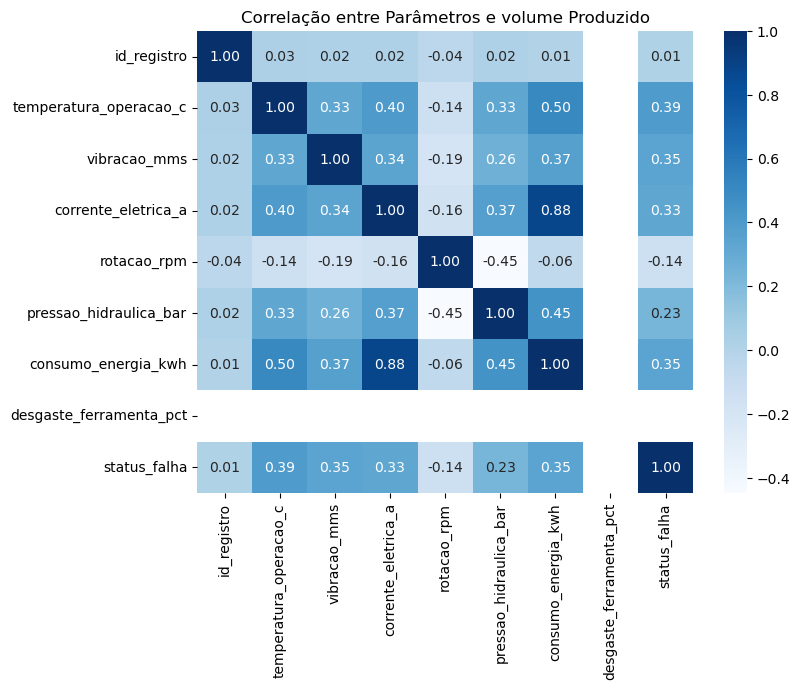

In [6]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only = True), annot=True, cmap='Blues', fmt='.2f')
plt.title('Correlação entre Parâmetros e volume Produzido')
plt.show()

In [7]:
x = df[['temperatura_operacao_c', 'vibracao_mms', 'corrente_eletrica_a', 'rotacao_rpm', 'pressao_hidraulica_bar']]
y_regressao_linear = df['consumo_energia_kwh']
y_arvore_regressora = df['status_falha']

x_treino_regressao_linear, x_teste_regressao_linear, y_treino_regressao_linear, y_teste_regressao_linear = train_test_split(x, y_regressao_linear, test_size=0.2, random_state=42)
x_treino_arvore_regressora, x_teste_arvore_regressora, y_treino_arvore_regressora, y_teste_arvore_regressora = train_test_split(x, y_arvore_regressora, test_size=0.2, random_state=42)

In [8]:
modelo_regressao_linear = LinearRegression()
modelo_arvore_regressora = RandomForestRegressor(random_state=42)

In [9]:
modelo_regressao_linear.fit(x_treino_regressao_linear, y_treino_regressao_linear)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [10]:
modelo_arvore_regressora.fit(x_treino_arvore_regressora, y_treino_arvore_regressora)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [11]:
previsao_regressao_linear = modelo_regressao_linear.predict(x_teste_regressao_linear)
previsao_arvore_regressora = modelo_arvore_regressora.predict(x_teste_arvore_regressora)

In [12]:
r2 = metrics.r2_score(y_teste_regressao_linear, previsao_regressao_linear)
mae = metrics.mean_absolute_error(y_teste_regressao_linear, previsao_regressao_linear)

print("=" * 55)
print("MODELO 1: REGRESSÃO LINEAR (Consumo de Energia)")
print("=" * 55)
print(f"Coeficiente de Determinação (R²): {r2:.4f} ({r2:.2%})")
print(f"Erro Médio Absoluto (MAE):        {mae:.4f} kWh\n")

MODELO 1: REGRESSÃO LINEAR (Consumo de Energia)
Coeficiente de Determinação (R²): 0.8327 (83.27%)
Erro Médio Absoluto (MAE):        1.7447 kWh



In [13]:
previsao_classe = previsao_arvore_regressora.round().astype(int)

acuracia = metrics.accuracy_score(y_teste_arvore_regressora, previsao_classe)
f1 = metrics.f1_score(y_teste_arvore_regressora, previsao_classe)
matriz_confusao = metrics.confusion_matrix(y_teste_arvore_regressora, previsao_classe)

print("=" * 55)
print("MODELO 2: RANDOM FOREST REGRESSOR (Status de Falha)")
print("=" * 55)
print(f"Acurácia: {acuracia:.4f} ({acuracia:.2%})")
print(f"F1-Score: {f1:.4f}")
print("\nMatriz de Confusão:")
print(matriz_confusao)
print("=" * 55)

MODELO 2: RANDOM FOREST REGRESSOR (Status de Falha)
Acurácia: 0.9670 (96.70%)
F1-Score: 0.8290

Matriz de Confusão:
[[887   3]
 [ 30  80]]


In [14]:
joblib.dump(modelo_regressao_linear, "modelo_regressao_energia.pkl")
joblib.dump(modelo_arvore_regressora, "modelo_arvore_falha.pkl")

['modelo_arvore_falha.pkl']